<a href="https://colab.research.google.com/github/arvin611ch/taica-lab07-sunzi-rag/blob/main/RAG01_build_sunzi_vector_db.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 07（程式一 RAG01）｜把《孫子兵法》十三篇向量化，建立 FAISS 向量資料庫，存成 `rag-data.zip`

- **繳交標題：** 陽明交大 113611097 百川 江晟維 孫子 AI 軍師（RAG）
- **知識來源：** 《孫子兵法》全文（春秋・孫武，公有領域；文字據維基文庫整理，13 篇、74 段、7,434 字）
- **這一本做什麼：** 讀 13 個 TXT → 每個「段落」切成一個文件 → EmbeddingGemma 2 向量化 → FAISS 精確搜尋索引 → 打包成 `rag-data.zip`。**不呼叫任何大語言模型、不需要金鑰。**
- **第二本（RAG02，對話機器人）：** https://colab.research.google.com/github/arvin611ch/taica-lab07-sunzi-rag/blob/main/RAG02_sunzi_strategist_chatbot.ipynb
- **原始碼、資料、截圖：** https://github.com/arvin611ch/taica-lab07-sunzi-rag
- **執行方式：** 直接「全部執行」即可（文本 zip 會自動從 GitHub 下載；沒網路時會改成請你上傳）。有 GPU 幾十秒，CPU 約 5～8 分鐘（小實驗要把 74 段向量化三次）。

## 作業重點說明（RAG01）

| 老師的 RAG_01 範例 | 這份作業 |
|---|---|
| 「大學生打工權益」16 篇教學摘要，**一篇一向量**、不切塊 | 《孫子兵法》13 篇文言文，**一段一向量**（74 段）：一篇最長 1,327 字、講好幾件事，整篇一向量會把不相干的段落混在一起；段落才是「一個觀念」的單位（§5） |
| 文件格式：標題／來源網址／【內容】 | 自己設計的格式：篇名／篇序／**主旨（我寫的白話一句）**／關鍵詞／來源／【原文】／**【白話輔助】（AI 逐段翻成白話，存進 metadata 給軍師看）**（§3、§4） |
| `extract_rag_text()`、`extract_metadata()` 兩個可修改函式 | 合併成一個 `parse_chapter()`，一次回傳段落清單＋白話清單＋metadata，並檢查兩者數量一致（§5） |
| 文件向量用 `title: none \| text: 正文` | **做了一個小實驗（§8）**：用 16 個現代問法的測試問題，比較「只有原文」「加篇名＋主旨」「再加白話輔助」三種送進 embedding 的寫法，看哪一種最能把白話問題對到文言段落；最後用最好的那種建庫 |
| 匯出 index.faiss／documents.json／index_doc_ids.json／config.json | 同樣四個檔案（第二本沿用老師的檢查邏輯），config 多記錄：文件單位、採用的模板、實驗結果；zip 檔名依作業規定叫 **`rag-data.zip`** |

為什麼要做 §8 的實驗：問題是白話（「期中考五科只夠讀三科怎麼辦」），文件是文言（「無所不備，則無所不寡」），embedding 模型不一定看得出兩者是同一件事。先量一下，再決定資料怎麼寫，比憑感覺好。

## 0. 固定套件

老師每份範例固定的 `%matplotlib inline`＋numpy／pandas／matplotlib，加上前幾次作業都有用的 seaborn。§6 與 §9 會用 pandas 整理表格、matplotlib 畫圖。

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. 安裝套件

和老師的 RAG_01 一樣鎖定版本：Sentence Transformers 載入 EmbeddingGemma 2、FAISS 做向量搜尋。

In [2]:
%pip install -q "sentence-transformers==6.1.0" "transformers==5.20.1" "faiss-cpu==1.15.1"

Note: you may need to restart the kernel to use updated packages.


## 2. 匯入套件與集中設定

- `DOCUMENT_TEMPLATE` 先放老師的寫法，§8 實驗後會換成表現最好的那個。
- `QUERY_TEMPLATE` 是 EmbeddingGemma 官方建議的查詢前綴，第二本程式要用一模一樣的字串。
- 文本 zip 從 GitHub 下載（`SOURCE_ZIP_URL`）；在我自己電腦的 repo 目錄裡執行時直接讀 `data/sunzi_source.zip`。

In [3]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import importlib.metadata as package_metadata
import hashlib, io, json, os, re, shutil, sys, tempfile, zipfile, urllib.request

import torch
import faiss
from IPython.display import display
from sentence_transformers import SentenceTransformer
from huggingface_hub import HfApi

IN_COLAB = "google.colab" in sys.modules
MODEL_ID = "google/embeddinggemma-2"
BATCH_SIZE = 8
EXPORT_ZIP_NAME = "rag-data.zip"                      # 作業規定的檔名
SOURCE_ZIP_URL = "https://github.com/arvin611ch/taica-lab07-sunzi-rag/raw/main/data/sunzi_source.zip"
DOCUMENT_TEMPLATE = "title: none | text: {text}"       # 先用老師的寫法，§9 之後會換
QUERY_TEMPLATE = "task: search result | query: {question}"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.bfloat16 if DEVICE == "cuda" and torch.cuda.is_bf16_supported() else torch.float32
PACKAGE_NAMES = ["torch", "numpy", "sentence-transformers", "transformers", "faiss-cpu", "huggingface-hub"]
PACKAGE_VERSIONS = {name: package_metadata.version(name) for name in PACKAGE_NAMES}
print("裝置：", DEVICE, "／模型精度：", DTYPE)
if DEVICE == "cuda":
    print("GPU：", torch.cuda.get_device_name(0))
display(pd.DataFrame(PACKAGE_VERSIONS.items(), columns=["套件", "版本"]))

/mnt/nvme0/home/arvin/taica_gen_ai/lab07/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


裝置： cuda ／模型精度： torch.bfloat16
GPU： NVIDIA GeForce RTX 5090


,套件,版本
0,torch,2.15.0
1,numpy,2.5.4
2,sentence-transformers,6.1.0
3,transformers,5.20.1
4,faiss-cpu,1.15.1
5,huggingface-hub,1.33.0


## 3. 取得文本：《孫子兵法》13 篇 TXT

文字來自維基文庫（公有領域），用 repo 裡的 `tools/fetch_sunzi.py` 清掉 wiki 標記、每篇一檔；每篇的「主旨」與「關鍵詞」是我自己寫的，「白話輔助」是用本機的 Qwen2.5-14B 逐段翻成白話、再人工抽查。白話輔助原本是想拿來幫助檢索（§8 的實驗會檢驗這件事），另外也會存進 metadata，讓第二本程式的軍師看得懂文言段落在講什麼；軍師只會引用原文，不會引用白話。

下面這格：先找本機的 `data/sunzi_source.zip`，沒有就從 GitHub 下載；都失敗（例如沒網路）就在 Colab 請你上傳。解壓縮時只解開 `.txt`，並沿用老師的做法檢查 zip 裡沒有奇怪的路徑。

In [4]:
if Path("data/sunzi_source.zip").exists():                     # 在 repo 目錄裡（本機）執行
    SOURCE_ZIP = Path("data/sunzi_source.zip")
else:
    SOURCE_ZIP = Path("sunzi_source.zip")
    if not SOURCE_ZIP.exists():
        try:
            urllib.request.urlretrieve(SOURCE_ZIP_URL, SOURCE_ZIP)
            print("已從 GitHub 下載：", SOURCE_ZIP_URL)
        except Exception as e:
            print("下載失敗：", e)
            if IN_COLAB:
                from google.colab import files
                uploaded = files.upload()
                SOURCE_ZIP.write_bytes(next(iter(uploaded.values())))
            else:
                raise
archive_bytes = SOURCE_ZIP.read_bytes()
SOURCE_ARCHIVE_SHA256 = hashlib.sha256(archive_bytes).hexdigest()
DATA_DIR = Path(tempfile.mkdtemp(prefix="sunzi_docs_"))

with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    members = [m for m in archive.infolist()
               if not m.is_dir() and m.filename.lower().endswith(".txt")
               and not any(part.startswith((".", "__MACOSX")) for part in Path(m.filename).parts)]
    if not members:
        raise ValueError("zip 裡找不到 TXT。")
    for m in members:
        target = (DATA_DIR / m.filename).resolve()
        if not target.is_relative_to(DATA_DIR.resolve()):
            raise ValueError(f"zip 包含不適當的路徑：{m.filename}")
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(archive.read(m))

txt_paths = sorted([p for p in DATA_DIR.rglob("*") if p.is_file() and p.suffix.lower() == ".txt"],
                   key=lambda p: p.relative_to(DATA_DIR).as_posix())
print("文本：", SOURCE_ZIP, f"（sha256 前 12 碼 {SOURCE_ARCHIVE_SHA256[:12]}）")
print("TXT 數量：", len(txt_paths))
for path in txt_paths:
    print("•", path.name)

文本： data/sunzi_source.zip （sha256 前 12 碼 e0eb0c18148b）
TXT 數量： 13
• 01_始計篇.txt
• 02_作戰篇.txt
• 03_謀攻篇.txt
• 04_軍形篇.txt
• 05_兵勢篇.txt
• 06_虛實篇.txt
• 07_軍爭篇.txt
• 08_九變篇.txt
• 09_行軍篇.txt
• 10_地形篇.txt
• 11_九地篇.txt
• 12_火攻篇.txt
• 13_用間篇.txt


## 4. 先看一篇原始文件

欄位設計：前面八行是 metadata（篇名、篇序、主旨、關鍵詞、來源…），`【原文】`之後每個段落空一行隔開，`【白話輔助】`之後是對應段落的白話翻譯（編號對應）。

不是每個欄位都要送進 embedding：**來源網址、日期、關鍵詞**只當 metadata；**篇名、主旨、原文、白話**才是檢索用的文字（§8 會比較要放哪些）。

In [5]:
SAMPLE_INDEX = 5          # 06_虛實篇
sample_path = txt_paths[SAMPLE_INDEX]
sample_raw = sample_path.read_text(encoding="utf-8-sig")
print("檔名：", sample_path.name)
print("=" * 60)
print(sample_raw)

檔名： 06_虛實篇.txt
篇名：虛實篇
篇序：6
維基文庫標題：虛實第六
主旨：主動權在我、不在敵：致人而不致於人；避實擊虛，攻其所不守、攻其所必救；讓敵人處處防備而分散，我則集中兵力；兵形象水，因敵而變。
關鍵詞：致人而不致於人、避實擊虛、攻其所必救、我專敵分、無所不備則無所不寡、兵形象水
原典：《孫子兵法》（春秋・孫武），公有領域；文字據維基文庫整理
來源網址：https://zh.wikisource.org/wiki/%E5%AD%AB%E5%AD%90%E5%85%B5%E6%B3%95
整理日期：2026-11-01

【原文】
孫子曰：凡先處戰地而待敵者佚，後處戰地而趨戰者勞。故善戰者，致人而不致於人。

能使敵自至者，利之也；能使敵不得至者，害之也。故敵佚能勞之，飽能饑之，安能動之。出其所不趨，趨其所不意。

行千里而不勞者，行於無人之地也。攻而必取者，攻其所不守也；守而必固者，守其所不攻也。故善攻者，敵不知其所守；善守者，敵不知其所攻。微乎微乎！至于無形；神乎神乎！至于無聲，故能為敵之司命。

進而不可禦者，沖其虛也；退而不可追者，速而不可及也。故我欲戰，敵雖高壘深溝，不得不與我戰者，攻其所必救也；我不欲戰，雖畫地而守之，敵不得與我戰者，乖其所之也。

故形人而我無形，則我專而敵分。我專為一，敵分為十，是以十攻其一也，則我衆而敵寡。能以衆擊寡者，則吾之所與戰者，約矣。吾所與戰之地不可知，不可知，則敵所備者多，敵所備者多，則吾之所與戰者寡矣。故備前則後寡，備後則前寡，備左則右寡，備右則左寡，無所不備，則無所不寡。寡者，備人者也；衆者，使人備己者也。

故知戰之地，知戰之日，則可千里而會戰；不知戰之地，不知戰之日，則左不能救右，右不能救左，前不能救後，後不能救前，而況遠者數十里，近者數里乎！以吾度之，越人之兵雖多，亦奚益於勝敗哉！故曰：勝可擅也。敵雖衆，可使無鬥。

故策之而知得失之計，作之而知動靜之理，形之而知死生之地，角之而知有餘不足之處。故形兵之極，至於無形。無形，則深間不能窺，智者不能謀。因形而措勝於衆，衆不能知。人皆知我所以勝之形，而莫知吾所以制勝之形。故其戰勝不復，而應形於無窮。

夫兵形象水，水之行，避高而趨下；兵之勝，避實而擊虛。水因地而制行，兵因敵而制勝。故兵無成勢，無恒形，能因敵變化而取勝者，謂之神。故五行無常勝，四時無常位，日

## 5. 可修改函式：`parse_chapter()` —— 一篇 TXT → 段落清單＋白話清單＋metadata

老師的範例是兩個函式（取正文、取 metadata）各回傳一件事；這裡因為「一篇要切成很多段」，合併成一個函式一次回傳：

- `paragraphs`：【原文】裡用空行隔開的段落（去掉所有空白）
- `paraphrases`：【白話輔助】裡「1. 2. 3.」開頭的句子；**數量必須和段落一樣**，不一樣就直接報錯，不會默默對錯位
- 其他欄位：篇名、篇序、主旨、關鍵詞（頓號分隔）、來源網址、整理日期

**換自己的資料主要改這個函式**：例如小說章節可以用「每 N 句切一段」，法規可以用「每一條切一段」。

In [6]:
def parse_chapter(raw_text, filename):
    """解析我自己設計的文件格式；換資料時修改這裡。"""
    normalized = raw_text.lstrip("﻿").replace("\r\n", "\n").replace("\r", "\n")
    if "【原文】" not in normalized:
        raise ValueError("找不到【原文】區段。")
    head, rest = normalized.split("【原文】", 1)
    body, _, tail = rest.partition("【白話輔助】")

    def field(name):
        m = re.search(rf"^{re.escape(name)}[：:][ \t]*(.*)$", head, flags=re.MULTILINE)
        return m.group(1).strip() if m and m.group(1).strip() else None

    paragraphs = [re.sub(r"\s+", "", p) for p in re.split(r"\n\s*\n", body) if p.strip()]
    paraphrases = [s.strip() for s in re.findall(r"^\d+\.\s*(.+)$", tail, flags=re.MULTILINE)] if tail else []
    if not paragraphs:
        raise ValueError("【原文】是空的。")
    if paraphrases and len(paraphrases) != len(paragraphs):
        raise ValueError(f"白話輔助有 {len(paraphrases)} 句，但原文有 {len(paragraphs)} 段，數量不符。")
    if field("篇序") is None or field("篇名") is None:
        raise ValueError("缺少篇序或篇名。")
    return {
        "chapter_no": int(field("篇序")), "chapter": field("篇名"), "gist": field("主旨"),
        "keywords": [k for k in (field("關鍵詞") or "").split("、") if k],
        "source_url": field("來源網址"), "date": field("整理日期"), "filename": filename,
        "paragraphs": paragraphs, "paraphrases": paraphrases,
    }

sample = parse_chapter(sample_raw, sample_path.name)
print(f"《{sample['chapter']}》（第 {sample['chapter_no']} 篇）主旨：{sample['gist']}")
print("關鍵詞：", "、".join(sample["keywords"]))
print(f"段落數 {len(sample['paragraphs'])}，白話數 {len(sample['paraphrases'])}")
print("\n第 5 段原文：", sample["paragraphs"][4])
print("第 5 段白話：", sample["paraphrases"][4] if sample["paraphrases"] else "（無）")

《虛實篇》（第 6 篇）主旨：主動權在我、不在敵：致人而不致於人；避實擊虛，攻其所不守、攻其所必救；讓敵人處處防備而分散，我則集中兵力；兵形象水，因敵而變。
關鍵詞： 致人而不致於人、避實擊虛、攻其所必救、我專敵分、無所不備則無所不寡、兵形象水
段落數 8，白話數 8

第 5 段原文： 故形人而我無形，則我專而敵分。我專為一，敵分為十，是以十攻其一也，則我衆而敵寡。能以衆擊寡者，則吾之所與戰者，約矣。吾所與戰之地不可知，不可知，則敵所備者多，敵所備者多，則吾之所與戰者寡矣。故備前則後寡，備後則前寡，備左則右寡，備右則左寡，無所不備，則無所不寡。寡者，備人者也；衆者，使人備己者也。
第 5 段白話： 所以，讓敵人顯露形迹而我方隱藏不露，就能使我方集中兵力而敵方兵力分散。我方兵力集中於一點，敵方兵力分散成十點，這樣就是以十個點攻打一個點，兵力就多而敵方兵力就少。能夠用多打少，那麼與我方交戰的敵人就少了。我方交戰的地點敵人無法預料，無法預料，敵人就要防備多處，敵人防備多處，那麼與我方交戰的地點就少了。因此，防備前面，後面就兵力不足；防備後面，前面就兵力不足；防備左面，右面就兵力不足；防備右面，左面就兵力不足。什麼地方都防備，那就什麼地方兵力都少了。兵力少的是被對方防備的；兵力多的是讓對方來防備自己的。


## 6. 批次整理成統一格式：一段一個文件

每個文件有 `doc_id`（`doc_篇序_段序`，例如 `doc_06_05` 是虛實篇第 5 段）、`text`（原文段落，之後軍師引用的就是這個）和 `metadata`（篇名、主旨、白話、關鍵詞、來源…）。編號只看檔案排序與段落順序，資料不變編號就不變。

順便用 pandas／matplotlib 看一下 13 篇各有幾段、幾個字：九地篇最長（8 段 1,327 字），火攻篇最短（3 段）。

In [7]:
chapters, documents = [], []
for path in txt_paths:
    try:
        raw = path.read_text(encoding="utf-8-sig")
        if "�" in raw:
            raise ValueError("文字含有替代字元，請檢查原始編碼。")
        ch = parse_chapter(raw, path.name)
    except (ValueError, UnicodeDecodeError) as exc:
        raise ValueError(f"處理失敗：{path.name}；原因：{exc}") from exc
    chapters.append(ch)
    for i, para in enumerate(ch["paragraphs"], start=1):
        documents.append({
            "doc_id": f"doc_{ch['chapter_no']:02d}_{i:02d}",
            "text": para,
            "metadata": {
                "title": f"{ch['chapter']} 第 {i} 段", "chapter_no": ch["chapter_no"], "chapter": ch["chapter"],
                "paragraph_no": i, "gist": ch["gist"], "keywords": ch["keywords"],
                "paraphrase": ch["paraphrases"][i - 1] if ch["paraphrases"] else None,
                "source_url": ch["source_url"], "date": ch["date"], "filename": ch["filename"], "chars": len(para),
            },
        })

index_doc_ids = [doc["doc_id"] for doc in documents]
assert len(set(index_doc_ids)) == len(index_doc_ids), "doc_id 重複"
documents_by_id = {doc["doc_id"]: doc for doc in documents}
has_paraphrase = all(doc["metadata"]["paraphrase"] for doc in documents)
print(f"{len(chapters)} 篇 → {len(documents)} 個文件（段落）；白話輔助齊全：{has_paraphrase}")

summary = pd.DataFrame([{"篇序": ch["chapter_no"], "篇名": ch["chapter"], "段落數": len(ch["paragraphs"]),
                         "字數": sum(len(p) for p in ch["paragraphs"]),
                         "最長段落": max(len(p) for p in ch["paragraphs"])} for ch in chapters]).set_index("篇序")
display(summary)
print("第一筆統一格式：")
print(json.dumps(documents[0], ensure_ascii=False, indent=2))

13 篇 → 74 個文件（段落）；白話輔助齊全：True


,篇名,段落數,字數,最長段落
篇序,,,,
1,始計篇,4,430,162
2,作戰篇,6,414,174
3,謀攻篇,8,507,104
4,軍形篇,5,373,113
5,兵勢篇,6,419,134
6,虛實篇,8,719,149
7,軍爭篇,6,581,174
8,九變篇,4,297,136
9,行軍篇,6,770,325


第一筆統一格式：
{
  "doc_id": "doc_01_01",
  "text": "孫子曰：兵者，國之大事，死生之地，存亡之道，不可不察也。故經之以五事，校之以計，而索其情：一曰道，二曰天，三曰地，四曰將，五曰法。",
  "metadata": {
    "title": "始計篇 第 1 段",
    "chapter_no": 1,
    "chapter": "始計篇",
    "paragraph_no": 1,
    "gist": "開戰前先把帳算清楚：用道、天、地、將、法五事與七計評估雙方勝算；兵者詭道，示弱藏強、攻其無備、出其不意。",
    "keywords": [
      "廟算",
      "五事七計",
      "知勝負",
      "詭道",
      "出其不意",
      "事前評估"
    ],
    "paraphrase": "孫子說：戰爭是國家的大事，關係著生死存亡，不能不仔細考察。所以要從五個方面來分析，比較雙方的策略，探求實情：一是政治，二是天時，三是地利，四是將領，五是法令。",
    "source_url": "https://zh.wikisource.org/wiki/%E5%AD%AB%E5%AD%90%E5%85%B5%E6%B3%95",
    "date": "2026-11-01",
    "filename": "01_始計篇.txt",
    "chars": 65
  }
}


使用字型： Noto Sans CJK TC


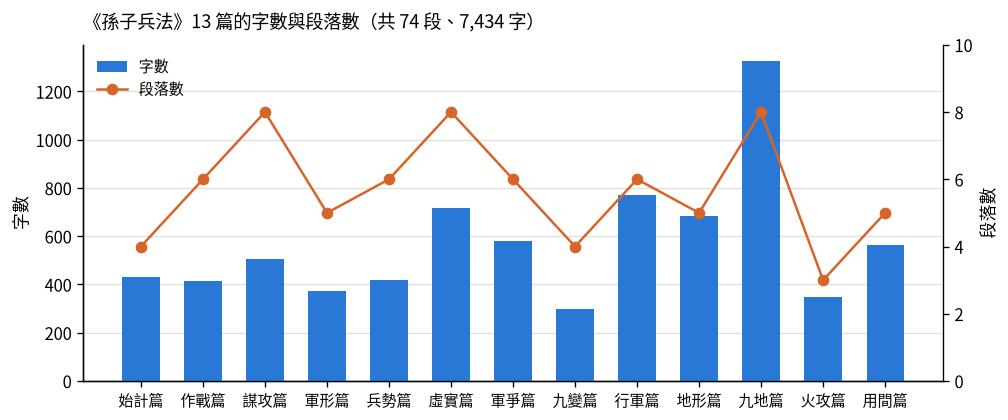

In [8]:
from matplotlib import font_manager

def set_cjk_font():
    """找一個有中文字的字型；Colab 預設沒有，就下載 Noto Sans CJK 的 OTF 版。"""
    wanted = ["Noto Sans CJK TC", "Noto Sans CJK JP", "Noto Sans TC", "Microsoft JhengHei", "PingFang TC", "Heiti TC"]
    have = {f.name for f in font_manager.fontManager.ttflist}
    for name in wanted:
        if name in have:
            plt.rcParams["font.family"] = [name, "DejaVu Sans"]
            return name
    try:
        url = "https://github.com/googlefonts/noto-cjk/raw/main/Sans/OTF/TraditionalChinese/NotoSansCJKtc-Regular.otf"
        path = "NotoSansCJKtc-Regular.otf"
        if not os.path.exists(path):
            urllib.request.urlretrieve(url, path)
        font_manager.fontManager.addfont(path)
        name = font_manager.FontProperties(fname=path).get_name()
        plt.rcParams["font.family"] = [name, "DejaVu Sans"]
        return name
    except Exception as e:
        print("找不到中文字型，圖上的中文可能變成方塊：", e)
        return None

print("使用字型：", set_cjk_font())
plt.rcParams["axes.unicode_minus"] = False

fig, ax1 = plt.subplots(figsize=(8.5, 3.6), dpi=120)
x = np.arange(len(summary))
ax1.bar(x, summary["字數"], width=0.6, color="#2a78d6", zorder=3, label="字數")
ax1.set_xticks(x, summary["篇名"], rotation=0, fontsize=9)
ax1.set_ylabel("字數")
ax1.grid(axis="y", color="#e1e0d9", linewidth=0.8, zorder=0)
for side in ("top", "right"):
    ax1.spines[side].set_visible(False)
ax2 = ax1.twinx()
ax2.plot(x, summary["段落數"], color="#d6652a", marker="o", linewidth=1.5, label="段落數")
ax2.set_ylabel("段落數")
ax2.set_ylim(0, summary["段落數"].max() + 2)
for side in ("top",):
    ax2.spines[side].set_visible(False)
ax1.set_title(f"《孫子兵法》13 篇的字數與段落數（共 {len(documents)} 段、{summary['字數'].sum():,} 字）", loc="left", fontsize=11, pad=10)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

## 7. 載入 EmbeddingGemma 2

和老師一樣：先查模型目前的 commit，鎖定版本載入，記進 config 讓第二本程式載同一版。只開文字部分（`vision_config`／`audio_config` 設 None）。

In [9]:
try:
    MODEL_REVISION = HfApi().model_info(MODEL_ID, token=False).sha
    model = SentenceTransformer(
        MODEL_ID, revision=MODEL_REVISION, token=False, device=DEVICE,
        config_kwargs={"vision_config": None, "audio_config": None},
        model_kwargs={"dtype": DTYPE, "attn_implementation": "eager"},
    )
except Exception as exc:
    raise RuntimeError("EmbeddingGemma 2 載入失敗。請確認網路、套件版本，必要時重新啟動工作階段；GPU 記憶體不足就改用 CPU。") from exc

DIMENSION = int(model.get_embedding_dimension())
TOKEN_LIMIT = min(2048, int(model.max_seq_length))
model.max_seq_length = TOKEN_LIMIT
print("模型：", MODEL_ID, "／版本：", MODEL_REVISION)
print("裝置：", model.device, "／精度：", model.dtype, "／向量維度：", DIMENSION, "／token 上限：", TOKEN_LIMIT)

Loading weights:   0%|          | 0/413 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 413/413 [00:00<00:00, 10420.35it/s]

模型： google/embeddinggemma-2 ／版本： f9972ac22e696a105c482202646979e33e4b5a1e
裝置： cuda:0 ／精度： torch.bfloat16 ／向量維度： 768 ／token 上限： 2048


In [10]:
def count_input_tokens(text):
    return len(model.tokenizer(text, add_special_tokens=True, truncation=False)["input_ids"])

def embed_texts(texts, batch_size=8, show_progress_bar=False):
    """文件或問題都走這裡：前綴已經自己加好（prompt=""），向量正規化成長度 1，內積＝cosine。"""
    vectors = model.encode(texts, prompt="", batch_size=batch_size, convert_to_numpy=True,
                           normalize_embeddings=True, show_progress_bar=show_progress_bar)
    vectors = np.ascontiguousarray(vectors, dtype=np.float32)
    if not np.isfinite(vectors).all() or np.any(np.linalg.norm(vectors, axis=1) <= 0):
        raise ValueError("向量含有 NaN／無限值或零向量。")
    faiss.normalize_L2(vectors)
    return vectors

def embed_question(question):
    if not isinstance(question, str) or not question.strip():
        raise ValueError("請輸入非空白問題。")
    query_input = QUERY_TEMPLATE.format(question=question.strip())
    if count_input_tokens(query_input) > TOKEN_LIMIT:
        raise ValueError("問題超過模型輸入長度上限，請縮短問題。")
    return embed_texts([query_input])

print("embedding 函式定義完成")

embedding 函式定義完成


## 8.（小實驗）文件要怎麼寫，白話問題才找得到文言段落？

16 個「現代人會這樣問」的測試問題，每題我先標好「應該找到哪幾篇」（主觀判斷，只看篇章層級）。比較三種送進 embedding 的寫法：

| 代號 | 文件向量的文字 | 想法 |
|---|---|---|
| A | `title: none \| text: 原文` | 老師的寫法 |
| B | `title: 篇名｜主旨 \| text: 原文` | 加上我寫的白話主旨，給模型一點「這段在講什麼」的提示 |
| C | `title: 篇名｜主旨 \| text: 白話輔助 + 原文` | 再加上 AI 逐段翻的白話，讓文件端也有現代語言 |

指標：hit@1（第一名是不是預期篇章）、hit@3（前三名有沒有命中）。相似度分數本身差距很小（0.68 vs 0.69），所以看排名比看分數有意義。

In [11]:
TEST_QUESTIONS = [
    ("期中考快到了，五科只夠認真讀三科，該怎麼取捨？", [6, 3]),
    ("跟室友吵架了，要不要正面對決？", [3]),
    ("明天要面試，前一晚該做哪些準備？", [1, 13]),
    ("專題報告一直拖，進度嚴重落後怎麼辦？", [2]),
    ("被老闆罵很生氣，想當場回嘴", [12, 7]),
    ("球賽對手比我們強很多，怎麼打？", [3, 4]),
    ("團隊士氣低落，身為組長要怎麼帶？", [7, 9, 10]),
    ("怎麼知道競爭對手的底細？", [13]),
    ("計畫趕不上變化，怎麼隨機應變？", [8, 6]),
    ("背水一戰真的有道理嗎？", [11]),
    ("談判的時候要不要先裝弱？", [1]),
    ("比賽贏了之後要注意什麼？", [12, 2]),
    ("去對方主場比賽，場地有影響嗎？", [10, 9, 6]),
    ("什麼時候該放棄、什麼時候該硬拚？", [3, 8]),
    ("怎麼讓對手搞不清楚我要做什麼？", [6, 1]),
    ("先搶到好位置再說，是這樣嗎？", [6, 7]),
]
TEMPLATES = {
    "A 只有原文": "title: none | text: {text}",
    "B 篇名＋主旨": "title: {chapter}｜{gist} | text: {text}",
    "C 篇名＋主旨＋白話": "title: {chapter}｜{gist} | text: {paraphrase}\n{text}",
}
if not has_paraphrase:
    TEMPLATES.pop("C 篇名＋主旨＋白話")
    print("提醒：白話輔助不齊全，跳過 C。")

def render_document(template, doc):
    m = doc["metadata"]
    return template.format(chapter=m["chapter"], gist=m["gist"] or "", paraphrase=m.get("paraphrase") or "", text=doc["text"])

query_vectors = embed_texts([QUERY_TEMPLATE.format(question=q) for q, _ in TEST_QUESTIONS])
cached_embeddings, exp_rows, exp_detail = {}, [], {}
for name, template in TEMPLATES.items():
    vectors = embed_texts([render_document(template, d) for d in documents], batch_size=BATCH_SIZE, show_progress_bar=True)
    cached_embeddings[name] = vectors
    idx = faiss.IndexFlatIP(DIMENSION); idx.add(vectors)
    scores, positions = idx.search(query_vectors, 3)
    hit1 = hit3 = 0; detail = []
    for (q, expected), pos, sc in zip(TEST_QUESTIONS, positions, scores):
        chs = [documents[int(p)]["metadata"]["chapter_no"] for p in pos]
        hit1 += chs[0] in expected; hit3 += any(c in expected for c in chs)
        detail.append({"問題": q, "期望篇": expected, "前三名": [index_doc_ids[int(p)] for p in pos], "分數": [round(float(s), 3) for s in sc]})
    exp_rows.append({"寫法": name, "hit@1": hit1, "hit@3": hit3, "題數": len(TEST_QUESTIONS)})
    exp_detail[name] = detail

exp_table = pd.DataFrame(exp_rows).set_index("寫法")
display(exp_table)
BEST = exp_table.sort_values(["hit@3", "hit@1"], ascending=False).index[0]
DOCUMENT_TEMPLATE = TEMPLATES[BEST]
print(f"採用：{BEST} → DOCUMENT_TEMPLATE = {DOCUMENT_TEMPLATE!r}")
print("\n採用寫法的逐題結果：")
display(pd.DataFrame(exp_detail[BEST]))

Batches:   0%|          | 0/10 [00:00<?, ?it/s]

Batches:  40%|████      | 4/10 [00:00<00:00, 33.71it/s]

Batches:  80%|████████  | 8/10 [00:00<00:00, 35.69it/s]

Batches: 100%|██████████| 10/10 [00:00<00:00, 36.08it/s]

Batches:   0%|          | 0/10 [00:00<?, ?it/s]

Batches:  30%|███       | 3/10 [00:00<00:00, 20.61it/s]

... (7 outputs left out)

Batches: 100%|██████████| 10/10 [00:00<00:00, 24.89it/s]

,hit@1,hit@3,題數
寫法,,,
A 只有原文,3,8,16
B 篇名＋主旨,7,10,16
C 篇名＋主旨＋白話,6,9,16


採用：B 篇名＋主旨 → DOCUMENT_TEMPLATE = 'title: {chapter}｜{gist} | text: {text}'

採用寫法的逐題結果：


,問題,期望篇,前三名,分數
0,期中考快到了，五科只夠認真讀三科，該怎麼取捨？,"[6, 3]","[doc_13_05, doc_13_02, doc_13_03]","[0.701, 0.7, 0.698]"
1,跟室友吵架了，要不要正面對決？,[3],"[doc_06_06, doc_13_04, doc_13_03]","[0.681, 0.677, 0.673]"
2,明天要面試，前一晚該做哪些準備？,"[1, 13]","[doc_13_04, doc_13_05, doc_01_02]","[0.638, 0.633, 0.623]"
3,專題報告一直拖，進度嚴重落後怎麼辦？,[2],"[doc_02_04, doc_07_02, doc_02_02]","[0.601, 0.594, 0.589]"
4,被老闆罵很生氣，想當場回嘴,"[12, 7]","[doc_02_04, doc_07_05, doc_06_02]","[0.634, 0.628, 0.623]"
5,球賽對手比我們強很多，怎麼打？,"[3, 4]","[doc_03_04, doc_03_05, doc_05_01]","[0.719, 0.718, 0.711]"
6,團隊士氣低落，身為組長要怎麼帶？,"[7, 9, 10]","[doc_03_05, doc_07_05, doc_09_05]","[0.703, 0.69, 0.69]"
7,怎麼知道競爭對手的底細？,[13],"[doc_03_04, doc_03_08, doc_04_02]","[0.703, 0.702, 0.699]"
8,計畫趕不上變化，怎麼隨機應變？,"[8, 6]","[doc_08_03, doc_08_02, doc_12_02]","[0.699, 0.692, 0.676]"
9,背水一戰真的有道理嗎？,[11],"[doc_06_06, doc_09_01, doc_04_01]","[0.731, 0.729, 0.728]"


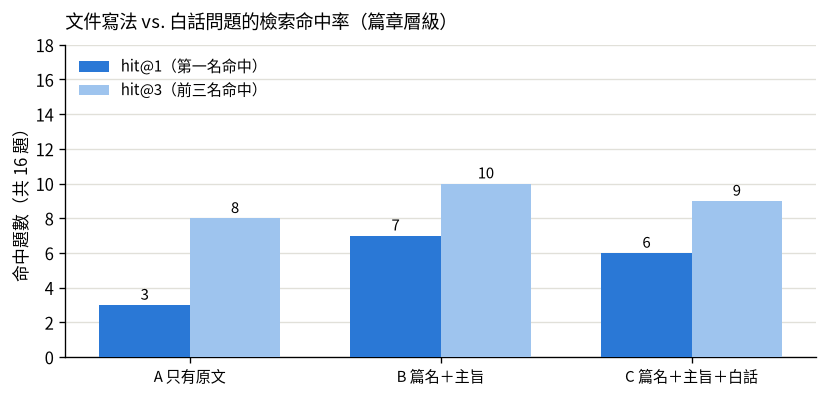

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.4), dpi=120)
x = np.arange(len(exp_table)); w = 0.36
b1 = ax.bar(x - w / 2, exp_table["hit@1"], w, color="#2a78d6", zorder=3, label="hit@1（第一名命中）")
b2 = ax.bar(x + w / 2, exp_table["hit@3"], w, color="#9ec4ee", zorder=3, label="hit@3（前三名命中）")
ax.bar_label(b1, padding=2, fontsize=9); ax.bar_label(b2, padding=2, fontsize=9)
ax.set_xticks(x, exp_table.index, fontsize=9)
ax.set_ylim(0, len(TEST_QUESTIONS) + 2); ax.set_ylabel(f"命中題數（共 {len(TEST_QUESTIONS)} 題）")
ax.set_title("文件寫法 vs. 白話問題的檢索命中率（篇章層級）", loc="left", fontsize=11, pad=10)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8, zorder=0)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

## 9. 用採用的寫法檢查輸入長度，避免靜默截斷

和老師一樣先算每個文件（含前綴）的 token 數，超過上限就停下來，不偷偷截掉後半段。段落最長 325 字，加白話也遠低於 2048。

In [13]:
document_inputs = [render_document(DOCUMENT_TEMPLATE, d) for d in documents]
token_counts = [count_input_tokens(t) for t in document_inputs]
length_table = pd.DataFrame({"doc_id": index_doc_ids, "tokens_含前綴": token_counts})
print(length_table["tokens_含前綴"].describe().round(1).to_string())
long_docs = [doc_id for doc_id, n in zip(index_doc_ids, token_counts) if n > TOKEN_LIMIT]
if long_docs:
    raise ValueError(f"以下文件超過 {TOKEN_LIMIT} tokens，請先調整資料：{long_docs}")
print(f"\n全部 {len(documents)} 個文件都在 {TOKEN_LIMIT} tokens 以內，不需要截斷。")
print("\n第一筆真正送入 embedding 的文字：\n" + document_inputs[0])

count     74.0
mean     167.1
std       57.7
min       90.0
25%      124.0
50%      154.0
75%      195.5
max      393.0

全部 74 個文件都在 2048 tokens 以內，不需要截斷。

第一筆真正送入 embedding 的文字：
title: 始計篇｜開戰前先把帳算清楚：用道、天、地、將、法五事與七計評估雙方勝算；兵者詭道，示弱藏強、攻其無備、出其不意。 | text: 孫子曰：兵者，國之大事，死生之地，存亡之道，不可不察也。故經之以五事，校之以計，而索其情：一曰道，二曰天，三曰地，四曰將，五曰法。


## 10. 產生文件向量、建立 FAISS 精確搜尋索引

§8 已經算過採用寫法的向量，直接拿來用（不用再算一次）。`IndexFlatIP`＋正規化向量＝cosine similarity 排名。FAISS 回傳的是「第幾個向量」，`index_doc_ids` 負責對回 `doc_id`。

In [14]:
embeddings = cached_embeddings[BEST]
assert embeddings.shape == (len(documents), DIMENSION)
index = faiss.IndexFlatIP(DIMENSION)
index.add(embeddings)
assert index.ntotal == len(index_doc_ids) == len(documents)
print("索引類型：", type(index).__name__, "／向量數：", index.ntotal, "／維度：", index.d)
print("矩陣形狀：", embeddings.shape, "／前 3 個向量長度：", np.linalg.norm(embeddings[:3], axis=1).round(6))

def search_documents(question, top_k=3):
    query_vector = embed_question(question)
    scores, positions = index.search(query_vector, min(int(top_k), index.ntotal))
    results = []
    for rank, (position, score) in enumerate(zip(positions[0], scores[0]), start=1):
        doc_id = index_doc_ids[int(position)]
        results.append({"rank": rank, "score": float(score), **documents_by_id[doc_id]})
    return results

QUESTION = "期中考快到了，五科只夠認真讀三科，該怎麼取捨？"
results = search_documents(QUESTION, 3)
display(pd.DataFrame([{"排名": r["rank"], "doc_id": r["doc_id"], "篇名": r["metadata"]["chapter"],
                       "cosine": round(r["score"], 4), "原文（前 40 字）": r["text"][:40] + "…"} for r in results]))
for r in results:
    print(f"\n[{r['doc_id']}] {r['metadata']['title']} ({r['score']:.4f})")
    print("原文：", r["text"])
    print("白話：", r["metadata"].get("paraphrase") or "（無）")

索引類型： IndexFlatIP ／向量數： 74 ／維度： 768
矩陣形狀： (74, 768) ／前 3 個向量長度： [1. 1. 1.]


,排名,doc_id,篇名,cosine,原文（前 40 字）
0,1,doc_13_05,用間篇,0.7016,昔殷之興也，伊摯在夏；周之興也，呂牙在殷。故明君賢將，能以上智為間者，必成大功。…
1,2,doc_13_02,用間篇,0.7008,故用間有五：有鄉間，有內間，有反間，有死間，有生間。五間俱起，莫知其道，是謂「神…
2,3,doc_13_03,用間篇,0.6986,故三軍之事，莫親於間，賞莫厚於間，事莫密於間，非聖智不能用間，非仁義不能使間，非…



[doc_13_05] 用間篇 第 5 段 (0.7016)
原文： 昔殷之興也，伊摯在夏；周之興也，呂牙在殷。故明君賢將，能以上智為間者，必成大功。此兵之要，三軍之所恃而動也。
白話： 當殷商興起時，伊摯在夏朝；周朝興起時，呂牙在殷商。所以明智的君主和賢能的將領，能夠利用聰明才智的人做間諜，必定能成就大業。這是用兵的重要之處，整個軍隊都依賴這一點來行動。

[doc_13_02] 用間篇 第 2 段 (0.7008)
原文： 故用間有五：有鄉間，有內間，有反間，有死間，有生間。五間俱起，莫知其道，是謂「神紀」，人君之寶也。鄉間者，因其鄉人而用之；內間者，因其官人而用之；反間者，因其敵間而用之；死間者，為誑事於外，令吾間知之，而傳於敵間也；生間者，反報也。
白話： 因此，使用間諜有五種方式：鄉間、內間、反間、死間、生間。五種間諜同時使用，敵人無法猜透，這就是「神妙的紀律」，是君主的寶貴策略。鄉間是利用敵方的本地人；內間是利用敵方的官員；反間是利用敵方的間諜；死間是散布假情報讓敵方間諜傳回去；生間是讓自己的間諜安全返回報告。

[doc_13_03] 用間篇 第 3 段 (0.6986)
原文： 故三軍之事，莫親於間，賞莫厚於間，事莫密於間，非聖智不能用間，非仁義不能使間，非微妙不能得間之實。微哉！微哉！無所不用間也。間事未發而先聞者，間與所告者皆死。
白話： 所以軍隊中的事，沒有比情報更親密的了，獎賞沒有比情報更重要的，事情沒有比情報更秘密的。不是聰明睿智的人不能使用情報，不是仁義之士不能指揮情報工作，不是心思細密的人不能得到情報的真相。真是太微妙了！真是太微妙了！任何地方都離不開情報的運用。如果情報還未採取行動就已經被敵人知道了，提供情報的人和洩露情報的人一律處死。


## 11. 保存索引、文件、編號對照與設定

和老師一樣四個檔案（第二本程式沿用老師的檢查）：`index.faiss`、`documents.json`、`index_doc_ids.json`、`config.json`。config 另外記錄：文件單位是「段落」、採用的 `DOCUMENT_TEMPLATE`、§8 的實驗結果、文本 zip 的雜湊。

In [15]:
EXPORT_DIR = Path(tempfile.mkdtemp(prefix="rag_index_"))
faiss.write_index(index, str(EXPORT_DIR / "index.faiss"))
for filename, data in [("documents.json", documents), ("index_doc_ids.json", index_doc_ids)]:
    (EXPORT_DIR / filename).write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")

config = {
    "format_version": "1.0",
    "created_at": datetime.now(ZoneInfo("Asia/Taipei")).isoformat(timespec="seconds"),
    "corpus": "《孫子兵法》十三篇（維基文庫，公有領域）",
    "model_id": MODEL_ID, "model_revision": MODEL_REVISION,
    "model_config_kwargs": {"vision_config": None, "audio_config": None},
    "dimension": DIMENSION, "normalize_embeddings": True, "index_type": "IndexFlatIP",
    "metric": "cosine_similarity_via_normalized_inner_product",
    "document_template": DOCUMENT_TEMPLATE, "document_template_name": BEST,
    "query_template": QUERY_TEMPLATE, "encode_prompt": "", "max_seq_length": TOKEN_LIMIT,
    "document_count": len(documents), "chapter_count": len(chapters),
    "document_unit": "one_paragraph_one_vector",
    "retrieval_experiment": exp_table.reset_index().to_dict(orient="records"),
    "package_versions": PACKAGE_VERSIONS, "build_device": DEVICE, "build_dtype": str(DTYPE),
    "source_archive": SOURCE_ZIP.name, "source_archive_sha256": SOURCE_ARCHIVE_SHA256,
    "file_sha256": {name: hashlib.sha256((EXPORT_DIR / name).read_bytes()).hexdigest()
                    for name in ["index.faiss", "documents.json", "index_doc_ids.json"]},
}
(EXPORT_DIR / "config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
print("已保存：")
for path in sorted(EXPORT_DIR.iterdir()):
    print(f"  {path.name} ({path.stat().st_size:,} bytes)")

已保存：
  config.json (1,851 bytes)
  documents.json (112,665 bytes)
  index.faiss (227,373 bytes)
  index_doc_ids.json (1,112 bytes)


## 12. 重新載入，驗證第二本程式要用的資料

從剛保存的檔案重新載入：檔案雜湊、文件數、維度、編號一致；再用同一個問題向量比對保存前後排名與分數，並和 NumPy 全矩陣內積的排序對照，確認「精確搜尋」名副其實。

In [16]:
loaded_config = json.loads((EXPORT_DIR / "config.json").read_text(encoding="utf-8"))
for name, expected_hash in loaded_config["file_sha256"].items():
    assert hashlib.sha256((EXPORT_DIR / name).read_bytes()).hexdigest() == expected_hash, f"檔案完整性檢查失敗：{name}"
loaded_index = faiss.read_index(str(EXPORT_DIR / "index.faiss"))
loaded_documents = json.loads((EXPORT_DIR / "documents.json").read_text(encoding="utf-8"))
loaded_ids = json.loads((EXPORT_DIR / "index_doc_ids.json").read_text(encoding="utf-8"))
assert loaded_index.ntotal == len(loaded_documents) == len(loaded_ids) == loaded_config["document_count"]
assert loaded_index.d == loaded_config["dimension"] and len(set(loaded_ids)) == len(loaded_ids)
assert loaded_documents == documents and loaded_ids == index_doc_ids

verification_query = embed_question(QUESTION)
k = 3
before_scores, before_positions = index.search(verification_query, k)
after_scores, after_positions = loaded_index.search(verification_query, k)
np.testing.assert_array_equal(before_positions, after_positions)
np.testing.assert_allclose(before_scores, after_scores, atol=1e-6, rtol=1e-6)
all_scores = (embeddings @ verification_query[0]).ravel()
np.testing.assert_allclose(after_scores[0], np.sort(all_scores)[::-1][:k], atol=1e-5, rtol=1e-5)
print("通過：檔案完整性、文件對照、索引維度、保存前後一致、精確搜尋檢查。")

通過：檔案完整性、文件對照、索引維度、保存前後一致、精確搜尋檢查。


## 13. 打包成 `rag-data.zip`

zip 根目錄就是四個檔案。在 Colab 會直接觸發下載；在本機（repo 目錄）會存到 `rag-data.zip`，推上 GitHub 之後第二本程式就用那個網址下載。

In [17]:
EXPORT_ZIP = Path(EXPORT_ZIP_NAME)
required_files = ["index.faiss", "documents.json", "index_doc_ids.json", "config.json"]
with zipfile.ZipFile(EXPORT_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for name in required_files:
        archive.write(EXPORT_DIR / name, arcname=name)
with zipfile.ZipFile(EXPORT_ZIP) as archive:
    assert archive.testzip() is None and set(archive.namelist()) == set(required_files)
print("檔名：", EXPORT_ZIP.resolve())
print("大小：", f"{EXPORT_ZIP.stat().st_size:,} bytes")
print("sha256：", hashlib.sha256(EXPORT_ZIP.read_bytes()).hexdigest())
if IN_COLAB:
    from google.colab import files
    files.download(str(EXPORT_ZIP))

檔名： /mnt/nvme0/home/arvin/taica_gen_ai/lab07/rag-data.zip
大小： 172,452 bytes
sha256： 988b70701f63baf43c91ea21c177b45616f6ace95335661852d65842a9b628c5


## 14. 換自己的資料要改哪裡／AI 協助說明

1. 準備「一篇一檔」的 UTF-8 TXT，格式自己設計，包成 zip，改 `SOURCE_ZIP_URL`（或直接上傳）。
2. 改 **`parse_chapter()`**：決定什麼是一個「文件」（段落？條文？章節？）、哪些欄位是 metadata。
3. 想試不同寫法就改 §8 的 `TEMPLATES`，實驗會自動挑最好的；也可以把 `TEST_QUESTIONS` 換成自己的題目。
4. 從 §6 之後重新執行、重新匯出；**不要混用舊索引與新文件**。

**AI 協助（依註三）：** 這本 notebook 的程式與說明是在 Claude Code 協作下、以老師的 RAG_01 為底改寫的；每段白話輔助由本機 Qwen2.5-14B 產生（`tools/make_paraphrases.py`），我逐篇抽查過。完整說明、prompt 與截圖在第二本的 §1、§11 與 repo 的 `ai_assist_log.md`。第二本（對話機器人）：https://colab.research.google.com/github/arvin611ch/taica-lab07-sunzi-rag/blob/main/RAG02_sunzi_strategist_chatbot.ipynb